# Depth of field and tilt-shift: what is sharp, and how to choose it

A lens focuses one plane. Everything else is blurred, but a blur smaller
than some acceptable circle of confusion $c$ (30 µm is the convention for
a full frame sensor) looks sharp, and the range of distances that stays
below it is the depth of field. Photographers control it with the
aperture. View camera users and owners of tilt-shift lenses have a second
control: tilting the lens tilts the plane of sharp focus, which can then
lie along a landscape or a table top instead of facing the camera.

This notebook covers:

1. depth of field and the hyperfocal distance of a thin lens, checked
   against a ray trace of the 50 mm double Gauss of notebook 90, and why
   at the same framing the depth of field barely depends on the focal
   length,
2. where diffraction takes over: the wave optical MTF of a defocused lens,
   and the optimum F-number for a given depth,
3. the Scheimpflug rule and Merklinger's hinge rule for a tilted lens,
   checked with a thin lens and with the tilted double Gauss, whose curved
   field bends the plane of focus,
4. the wedge of sharp focus that replaces the depth of field of a tilted
   lens, and a rendered meadow that compares stopping down with tilting.

Notebook 90 derived the size of the blur itself (thin lens, pupils, real
rays) and showed its shape. Here the blur size is used to answer the
photographer's questions.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq, minimize_scalar
from scipy.signal import fftconvolve

from pyoptics import photography as ph
from pyoptics import raytrace as rt
from pyoptics import sensor as se
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
C = 0.03            # circle of confusion for a full frame sensor (mm)
LAM = 550e-6        # mm

## 1. Depth of field and the hyperfocal distance

A thin lens of focal length $f$ at $f/N$, focused at the distance $s_f$,
images a point at $s$ as a disk of diameter

$$c(s) = \frac{f^2}{N}\,\frac{\vert 1/s_f - 1/s\vert}{1 - f/s_f}$$

(`ph.blur_diameter()`). Setting $c(s) = c$ gives the limits of the depth of
field, $1/s = 1/s_f \pm (Nc/f^2)(1 - f/s_f)$ (`ph.dof_limits()`). The far
limit reaches infinity when the lens is focused at the hyperfocal distance
$H = f^2/Nc + f$. Focused there, everything from about $H/2$ to infinity is
acceptably sharp (`ph.hyperfocal_distance()`).

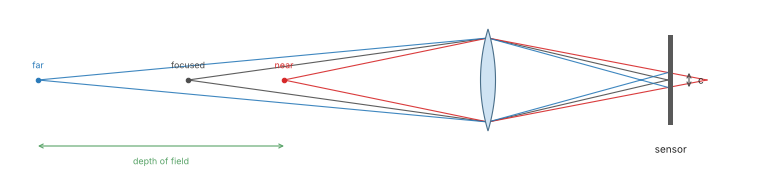

In [2]:
fig, ax = plt.subplots(figsize=(12, 3.6))
sketch.depth_of_field(ax)
plt.show()

f = 50.00 mm, f/8, c = 0.03 mm: hyperfocal distance 10466 mm
 focus (m)   near: thin lens   traced     far: thin lens   traced


    1.00          916 mm           917       1100 mm          1100 mm


    3.00         2338 mm          2341       4185 mm          4178 mm


    6.00         3819 mm          3825      13993 mm         13942 mm


   10.47         5233 mm          5243      infinity       4900612 mm


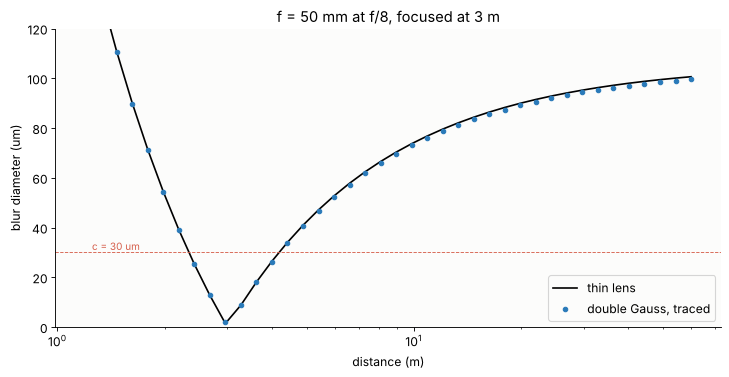

In [3]:
# depth of field of the double Gauss at f/8: thin lens limits against the ray trace
N = 8
lens = ph.double_gauss(N)
par = lens.paraxial()
f, Hz = par.efl, par.cardinal_points.H          # focal length; front principal plane behind the first vertex
H = ph.hyperfocal_distance(f, N, C)
print("f = {:.2f} mm, f/{}, c = {} mm: hyperfocal distance {:.0f} mm".format(f, N, C, H))

def traced_blur(focused, d, n=4000):
    """Blur diameter 2 sqrt(2) x rms radius (the diameter of a uniform disk) of an axial point at d
    in front of the first vertex."""
    s = rt.System(focused.surfaces, focused.stop_index, focused.wavelength, object_distance=d,
                  object_height=1.0)
    fp = ph.point_footprint(s, 0.0, n, np.random.default_rng(0))
    return 2*np.sqrt(2*np.average(fp.x**2 + fp.y**2, weights=fp.weight))

print(" focus (m)   near: thin lens   traced     far: thin lens   traced")
rows = []
for s_f in (1000.0, 3000.0, 6000.0, H):
    fs = ph.focus(lens, s_f - Hz)                      # distances from the front principal plane
    near_t, far_t = ph.dof_limits(f, N, C, s_f)
    near = brentq(lambda d: traced_blur(fs, d) - C, 0.2*(s_f - Hz), s_f - Hz, xtol=0.1) + Hz
    try:
        far = brentq(lambda d: traced_blur(fs, d) - C, s_f - Hz, 1e7, xtol=1.0) + Hz
    except ValueError:
        far = np.inf
    rows.append((s_f, near_t, near, far_t, far))
    print("{:8.2f}     {:8.0f} mm      {:8.0f}    {:>10s}       {:>10s}".format(
        s_f/1e3, near_t, near, "{:.0f} mm".format(far_t) if np.isfinite(far_t) else "infinity",
        "{:.0f} mm".format(far) if np.isfinite(far) else "infinity"))

# the blur against distance, focused at 3 m
fs = ph.focus(lens, 3000.0 - Hz)
d = np.geomspace(1200, 60000, 40)
fig, ax = plt.subplots(figsize=(9, 4.6), layout="constrained")
ax.semilogx(d/1e3, ph.blur_diameter(f, N, 3000.0, d)*1e3, color="k", lw=1.5, label="thin lens")
ax.semilogx(d/1e3, [traced_blur(fs, x - Hz, 2000)*1e3 for x in d], "o", color=BLUE, ms=4, label="double Gauss, traced")
ax.axhline(C*1e3, color=RED, lw=0.8, ls="--")
ax.text(1.25, C*1e3 + 1, "c = 30 um", color=RED, fontsize=9)
ax.set_xlabel("distance (m)"); ax.set_ylabel("blur diameter (um)"); ax.set_ylim(0, 120)
ax.set_title("f = 50 mm at f/8, focused at 3 m"); ax.legend()
plt.show()

The real lens agrees with the thin lens formulas when the distances are
measured from its front principal plane, 36.7 mm behind the first vertex.
The near limits agree to 0.3 % and the far limits to 0.5 %, as far as 6 m.
Focused at the hyperfocal distance, the traced far limit lies at 4.9 km
instead of infinity. Close to infinity the blur grows so slowly that a
small focus error from spherical aberration moves the limit a long way.
The traced blur follows the thin lens curve at every distance, including
in the asymmetry: the depth of field reaches about twice as far behind the
focus as in front of it.

A common question is whether a wide angle lens has more depth of field. At
the same F-number and the same framing of the subject (the same
magnification $m$), it hardly does. For distances well below $H$, the
depth is $2Nc(1+m)/m^2$, with no $f$ in it:

In [4]:
# the same framing with different lenses: a subject 1 m wide filling 36 mm (m = 0.036), f/8
print(" f (mm)   distance (m)   near (m)   far (m)   depth (m)   2 N c (1 + m)/m**2 (m)")
m = 0.036
for f_ in (24.0, 50.0, 135.0):
    s = f_*(1 + 1/m)
    near, far = ph.dof_limits(f_, 8, C, s)
    print("{:6.0f}     {:8.2f}       {:6.3f}    {:6.3f}     {:6.3f}       {:.3f}".format(
        f_, s/1e3, near/1e3, far/1e3, (far - near)/1e3, 2*8*C*(1 + m)/m**2/1e3))

 f (mm)   distance (m)   near (m)   far (m)   depth (m)   2 N c (1 + m)/m**2 (m)
    24         0.69        0.541     0.956      0.416       0.384
    50         1.44        1.270     1.660      0.391       0.384
   135         3.88        3.702     4.087      0.385       0.384


All three lenses give about 0.4 m. The wide angle lens has a little more
depth behind the subject, which is where the difference lies: a 24 mm lens
renders a distant background much less blurred than a 135 mm lens. The
background is shown smaller, but the depth around the subject is the
same.

## 2. Defocus and diffraction: the optimum aperture

Stopping down shrinks the geometric blur in proportion to $1/N$ and
enlarges the Airy disk, $2.44\lambda N$. Where they meet, closing the lens
further makes everything softer. A sensor at the distance $\Delta z$ from the
focus sees a wavefront with the defocus $W_{020} = \Delta z/8N^2$, and the
MTF is the autocorrelation of the defocused pupil (Hopkins,
`ph.defocus_mtf()`):

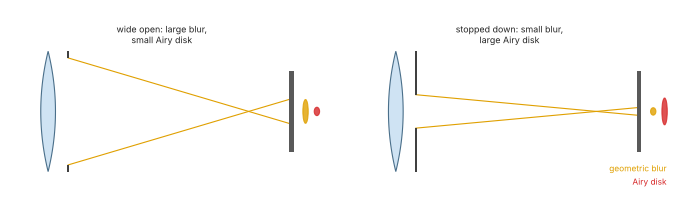

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.4))
sketch.defocus_and_diffraction(ax)
plt.show()

check in focus: largest difference to the diffraction MTF 6.1e-04
depth between the images of 2 m and infinity: 1.282 mm; Hansma's optimum N = 21.9
 frequency   best N (wave optics)   MTF there   at f/8   at f/45


   10 lp/mm        f/22.0             0.781      0.411    0.679


   20 lp/mm        f/24.5             0.553      0.090    0.387


   40 lp/mm        f/23.5             0.265      0.050    0.001


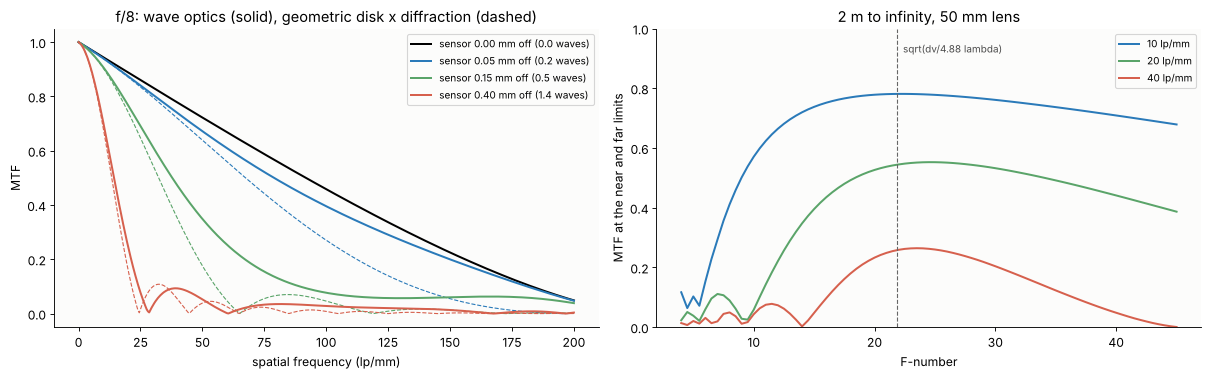

In [6]:
# wave optical MTF of defocus against diffraction alone and the geometric blur disk
fq = np.linspace(0, 200, 401)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), layout="constrained")
N = 8
print("check in focus: largest difference to the diffraction MTF {:.1e}".format(
    np.max(np.abs(ph.defocus_mtf(fq, N, 0.0, LAM) - se.diffraction_mtf(fq, LAM, N)))))
for dz, col in ((0.0, "k"), (0.05, BLUE), (0.15, GREEN), (0.4, RED)):
    w = dz/(8*N**2)/LAM
    m = ph.defocus_mtf(fq, N, dz, LAM, n_pupil=256)
    ax[0].plot(fq, m, color=col, lw=1.8, label="sensor {:.2f} mm off ({:.1f} waves)".format(dz, w))
    if dz > 0:
        ax[0].plot(fq, ph.geometric_defocus_mtf(fq, dz/N)*se.diffraction_mtf(fq, LAM, N), color=col,
                   lw=1, ls="--")
ax[0].set_xlabel("spatial frequency (lp/mm)"); ax[0].set_ylabel("MTF")
ax[0].set_title("f/8: wave optics (solid), geometric disk x diffraction (dashed)"); ax[0].legend(fontsize=9)

# a landscape from 2 m to infinity with a 50 mm lens: the sensor halfway between the two images
dv = 50*2000/1950 - 50
Ns = np.linspace(4, 45, 83)
N_h = ph.optimum_f_number(dv, LAM)
print("depth between the images of 2 m and infinity: {:.3f} mm; Hansma's optimum N = {:.1f}".format(dv, N_h))
print(" frequency   best N (wave optics)   MTF there   at f/8   at f/45")
for f0, col in ((10, BLUE), (20, GREEN), (40, RED)):
    ex = np.array([ph.defocus_mtf(f0, N_, dv/2, LAM) for N_ in Ns])
    ax[1].plot(Ns, ex, color=col, lw=1.8, label="{} lp/mm".format(f0))
    k = np.argmax(ex)
    print("  {:3d} lp/mm        f/{:.1f}             {:.3f}      {:.3f}    {:.3f}".format(
        f0, Ns[k], ex[k], np.interp(8, Ns, ex), ex[-1]))
ax[1].axvline(N_h, color="0.4", lw=1, ls="--")
ax[1].text(N_h + 0.5, 0.92, "sqrt(dv/4.88 lambda)", fontsize=9, color="0.3")
ax[1].set_xlabel("F-number"); ax[1].set_ylabel("MTF at the near and far limits")
ax[1].set_title("2 m to infinity, 50 mm lens"); ax[1].set_ylim(0, 1); ax[1].legend(fontsize=9)
plt.show()

In focus the FFT reproduces the diffraction MTF to $6\times10^{-4}$. For
a few waves of defocus the MTF falls quickly and then oscillates: its
zeros and negative lobes are the contrast reversals of spurious resolution.
The product of the geometric blur disk ($\vert 2J_1(x)/x\vert$,
$x = \pi c f$) and the diffraction MTF is only a rough model. It puts the
first zero in the right place for large defocus but underestimates the
MTF for small defocus, up to a wave or so.

For a landscape from 2 m to infinity with a 50 mm lens, the two images lie
1.28 mm apart, and the sensor is best placed halfway between them. The
geometric blur at both ends is then $1.28/(2N)$ mm. Equating it with the
Airy diameter gives Hansma's rule,
$N = \sqrt{\Delta v/4.88\lambda} = 21.9$ (`ph.optimum_f_number()`). The wave
optical MTF at the two ends is highest at f/22 to f/24.5 for 10, 20 and
40 lp/mm alike. The simple rule is right to within a third of a stop. At
f/8, the near and far ends are blurred far below the optimum, and at f/45
diffraction has wiped out 40 lp/mm. The geometric depth of field formulas
of section 1 ignore this. At f/22 and beyond, the Airy disk is as large as
the circle of confusion itself.

## 3. Tilting the lens: the Scheimpflug and hinge rules

When the lens is tilted against the sensor, the plane of sharp focus is no
longer parallel to the sensor. A thin lens images every plane to a plane,
and the plane of focus is the image of the sensor plane. Two rules locate
it:

- **Scheimpflug rule:** the sensor plane, the lens plane and the plane of
  focus meet in one line.
- **Hinge rule (Merklinger):** the plane of focus also passes through the
  line where the front focal plane of the lens meets the plane through the
  lens parallel to the sensor. For a tilt $\theta$ that line lies
  $J = f/\sin\theta$ from the lens (`ph.hinge_distance()`).

Together they fix the plane. The tilt sets $J$, and focusing (moving the
sensor) only swings the plane of focus about the hinge line:

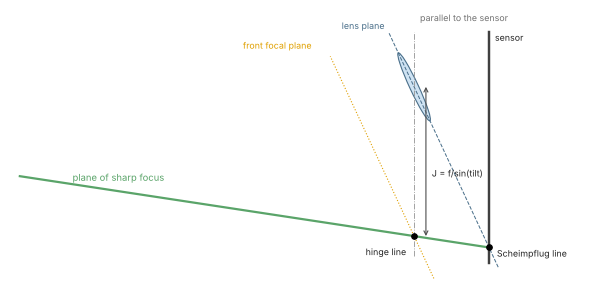

In [7]:
fig, ax = plt.subplots(figsize=(12, 4.4))
sketch.scheimpflug_hinge(ax)
plt.show()

In [8]:
# a thin lens tilted by 2.9 deg, 1 m above the ground: the plane of focus is the image of the sensor plane
f = 50.0
h = 1000.0
tilt = np.arcsin(f/h)                       # J = f/sin(tilt) = h: the hinge line lies on the ground
print("tilt {:.2f} deg, hinge distance J = {:.0f} mm".format(np.degrees(tilt), ph.hinge_distance(f, tilt)))
print(" lens to sensor   plane of focus: hinge y (mm)   angle to the axis   Scheimpflug line y (mm)")
for v in (50.0, 50.06, 50.2, 50.6):
    (y0, _), ang, yS = ph.plane_of_focus(f, tilt, v)
    print("   {:6.2f} mm          {:9.1f}                  {:7.3f} deg            {:9.1f}".format(
        v, y0, np.degrees(ang), yS))
v_ground = h*np.tan(tilt)
print("with the sensor at h tan(tilt) = {:.3f} mm the hinge and the Scheimpflug line both lie at y = -h:"
      " the plane of focus is the ground".format(v_ground))
# check the Scheimpflug rule: the plane of focus, the lens plane and the sensor plane share one line
for v in (50.2, 50.6):
    (y0, _), ang, yS = ph.plane_of_focus(f, tilt, v)
    z_s = v                                                   # the Scheimpflug line lies in the sensor plane
    y_pof = y0 - np.tan(ang)*z_s                              # height of the plane of focus at z = v
    print("v = {} mm: plane of focus at z = v: y = {:.3f} mm, Scheimpflug line y = {:.3f} mm".format(v, y_pof, yS))

tilt 2.87 deg, hinge distance J = 1000 mm
 lens to sensor   plane of focus: hinge y (mm)   angle to the axis   Scheimpflug line y (mm)
    50.00 mm            -1000.0                   -1.433 deg               -998.7
    50.06 mm            -1000.0                   -0.060 deg               -999.9
    50.20 mm            -1000.0                    3.129 deg              -1002.7
    50.60 mm            -1000.0                   11.977 deg              -1010.7
with the sensor at h tan(tilt) = 50.063 mm the hinge and the Scheimpflug line both lie at y = -h: the plane of focus is the ground
v = 50.2 mm: plane of focus at z = v: y = -1002.744 mm, Scheimpflug line y = -1002.744 mm
v = 50.6 mm: plane of focus at z = v: y = -1010.734 mm, Scheimpflug line y = -1010.734 mm


With the camera 1 m above the ground, a tilt of
$\arcsin(f/h) = 2.87°$ puts the hinge line on the ground. Every sensor
distance then gives a plane of focus through the same hinge, and the
focusing only turns it. At $v = h\tan\theta = 50.063$ mm the Scheimpflug
line reaches the ground too, and the plane of focus is the ground itself:
from the camera's feet to the horizon, everything on it is in focus at any
aperture. The plane through the image of the sensor (`ph.plane_of_focus()`)
meets the Scheimpflug line exactly, as the rule says.

The real double Gauss, tilted by the same angle about its front principal
point (`ph.tilt_lens()`, built from coordinate breaks), is traced from points
on the ground and above it (`ph.trace_point()`). For each sensor height,
the best focus along the line of sight is compared with two predictions.
The first is the thick lens version of the thin lens map: object distances
from the front principal point, image distances from the rear one, with
the focus shift of the real lens on its axis. The second also includes the
focus shift at that height, the field curvature of the lens, measured with
`ph.focus()`:

In [9]:
# the double Gauss at f/8, tilted by the same angle about its front principal point, traced
N = 8
lens = ph.double_gauss(N)
par = lens.paraxial()
f = par.efl
Hz, Hpz = par.cardinal_points.H, par.cardinal_points.H_prime
tilt = np.arcsin(f/h)
nrm = ph.lens_normal(tilt)
Hpos = np.array([0.0, 0.0, Hz])
Hp = Hpos + (Hpz - Hz)*nrm                     # rear principal point, tilted with the lens

# focus shift of the real lens (spherical aberration, field curvature) for an object at infinity,
# against the height on the sensor measured from the lens axis
fracs = np.linspace(0, 0.5, 6)
heights = f*np.tan(np.radians(23.4)*fracs)
shift = np.array([ph.focus(lens, field=q).surfaces[-1].thickness - par.bfl for q in fracs])
# sensor where a paraxial lens would have it (thick lens version of v = h tan(tilt)), moved by the
# focus shift on the axis so that the real lens focuses the ground near its axis
sensor_z = Hz + h*np.tan(tilt) + (Hpz - Hz)*np.cos(tilt) + shift[0]
tilted = ph.tilt_lens(lens, tilt, Hz, image_distance=sensor_z - Hz)
y_axis = (sensor_z - Hp[2])*np.tan(tilt)       # where the tilted lens axis meets the sensor

def predict(ys, curved):
    """Object point (thick lens collineation) of the sensor point at height ys, with the real lens'
    focus shift on the axis, or with the shift at that height (field curvature)."""
    P = np.array([0.0, ys, sensor_z])
    d = np.interp(abs(ys - y_axis), heights, shift) if curved else shift[0]
    P = P - d*nrm                               # the paraxial image the real focus stands for
    a_ = (P - Hp) @ nrm
    a = f*a_/(a_ - f)
    return Hpos - (a/a_)*(P - Hp)

def rms(X):
    x, y = ph.trace_point(tilted, X, 3000, np.random.default_rng(1))
    return np.sqrt(x.var() + y.var())

print("lens axis meets the sensor at y = {:.2f} mm; focus shift on the axis {:+.3f} mm, 8 mm off the axis {:+.3f} mm".format(
    y_axis, shift[0], np.interp(8, heights, shift)))
print(" sensor y   flat field: distance, height   traced best: distance, height   curved field: distance, height")
for ys in (1.0, 2.0, 4.0, 7.0, 10.0):
    Qf, Qc = predict(ys, False), predict(ys, True)
    r = minimize_scalar(lambda t: rms(Hpos + t*(Qf - Hpos)), bounds=(0.5, 1.2), method="bounded",
                        options={"xatol": 1e-4})
    Qb = Hpos + r.x*(Qf - Hpos)
    print("  {:5.1f}       {:6.2f} m {:+6.0f} mm           {:6.2f} m {:+6.0f} mm              {:6.2f} m {:+6.0f} mm".format(
        ys, -Qf[2]/1e3, Qf[1] + h, -Qb[2]/1e3, Qb[1] + h, -Qc[2]/1e3, Qc[1] + h))

lens axis meets the sensor at y = 2.50 mm; focus shift on the axis -0.032 mm, 8 mm off the axis -0.153 mm
 sensor y   flat field: distance, height   traced best: distance, height   curved field: distance, height
    1.0        39.78 m     -1 mm            37.99 m    +44 mm               36.33 m    +86 mm
    2.0        22.14 m     -0 mm            22.09 m     +2 mm               21.76 m    +17 mm
    4.0        11.72 m     -0 mm            11.39 m    +28 mm               11.40 m    +27 mm


    7.0         6.86 m     -0 mm             6.08 m   +113 mm                6.18 m    +99 mm
   10.0         4.84 m     -0 mm             3.87 m   +199 mm                4.01 m   +172 mm


Near the lens axis (1 to 4 mm on the sensor) the plane of focus lies on
the ground within 5 cm. Further out the real lens focuses closer than the
flat-field prediction. 10 mm from the centre of the sensor, which is 7.5 mm
from the lens axis, the plane of focus lies 0.2 m above the ground at 4 m,
instead of on it. The double Gauss has the field curvature of a lens that
is soft off the axis: its focus is 0.15 mm closer at 8 mm image height. The
prediction that includes that shift follows the traced points to within
5 % in distance. A real tilted lens therefore has a curved surface of
sharp focus, which is the image of its curved field. The Scheimpflug and
hinge rules describe the plane that this surface touches near the lens
axis.

## 4. The wedge of sharp focus

A tilted lens still has a depth of field, but its limits are planes as
well. They are the images of the two planes parallel to the sensor at
which the blur reaches $c$. They pass through the hinge line too, so the
zone of acceptable sharpness is a wedge. Merklinger's rule gives its size:
at the hyperfocal distance $H$ the near and far limits lie $J$ above and
below the plane of focus, measured parallel to the sensor, and the wedge
grows in proportion to the distance:

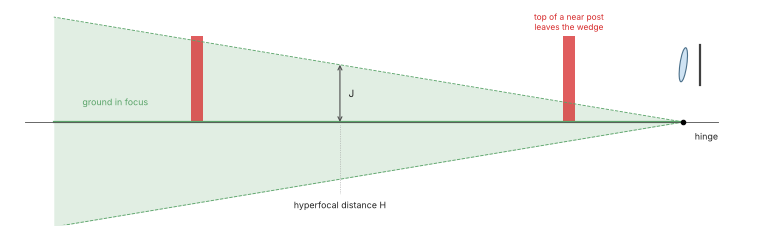

In [10]:
fig, ax = plt.subplots(figsize=(12, 4.0))
sketch.dof_wedge(ax)
plt.show()

hyperfocal distance 10.47 m, J = 1.00 m
 distance   upper limit above the ground   lower limit below it   rule: J d/H
   2.00 m         0.187 m                       0.187 m            0.191 m
   5.00 m         0.475 m                       0.476 m            0.478 m
  10.47 m         0.998 m                       1.000 m            1.000 m
  20.00 m         1.908 m                       1.916 m            1.911 m


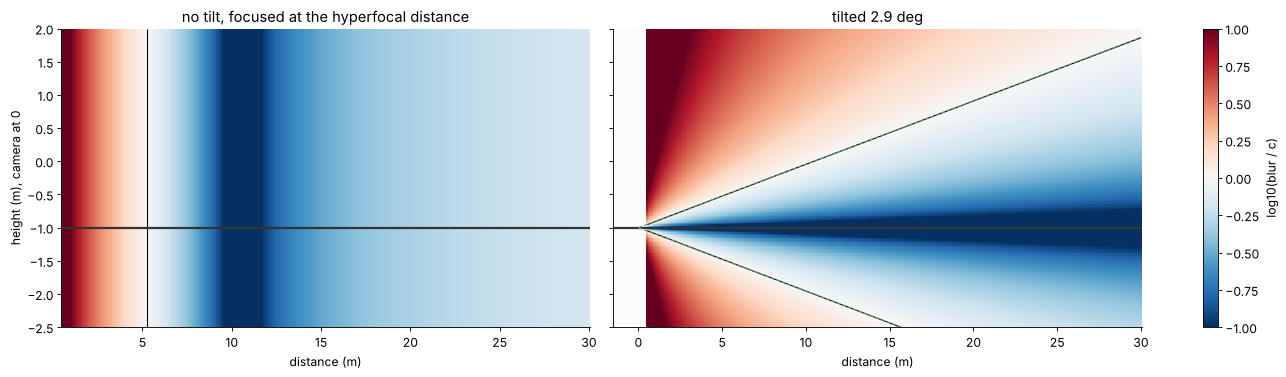

In [11]:
# depth of field of the tilted lens (thin lens, f/8, c = 30 um): where the blur reaches c above and
# below the ground, against Merklinger's rule (limits through the hinge, J above and below at the
# hyperfocal distance)
f, N = 50.0, 8
v = h*np.tan(tilt)
Hf = ph.hyperfocal_distance(f, N, C)
J = ph.hinge_distance(f, tilt)

def blur_at(y, z):
    return ph.tilted_blur(np.array([[0.0, y, z]]), f, N, tilt, v)[0]

print("hyperfocal distance {:.2f} m, J = {:.2f} m".format(Hf/1e3, J/1e3))
print(" distance   upper limit above the ground   lower limit below it   rule: J d/H")
dist = np.array([2000.0, 5000.0, Hf, 20000.0])
for dd in dist:
    up = brentq(lambda y: blur_at(y, -dd) - C, -h, -h + 5*J*dd/Hf)
    lo = brentq(lambda y: blur_at(y, -dd) - C, -h - 5*J*dd/Hf, -h)
    print("{:7.2f} m      {:8.3f} m                    {:8.3f} m            {:.3f} m".format(
        dd/1e3, (up + h)/1e3, (-h - lo)/1e3, J*dd/Hf/1e3))

# the blur map in the vertical plane through the axis
zz = np.linspace(-30000, -500, 300)
yy = np.linspace(-2500, 2000, 220)
Z, Y = np.meshgrid(zz, yy)
pts = np.stack([np.zeros(Z.size), Y.ravel(), Z.ravel()], axis=1)
B = ph.tilted_blur(pts, f, N, tilt, v).reshape(Z.shape)
B0 = ph.blur_diameter(f, N, ph.hyperfocal_distance(f, N, C), -Z)          # untilted, focused at hyperfocal
fig, ax = plt.subplots(1, 2, figsize=(16, 4.6), layout="constrained", sharey=True)
for a, b, title in ((ax[0], B0, "no tilt, focused at the hyperfocal distance"), (ax[1], B, "tilted 2.9 deg")):
    im = a.pcolormesh(-zz/1e3, yy/1e3, np.log10(np.maximum(b, 1e-6)/C), cmap="RdBu_r", vmin=-1, vmax=1, shading="auto")
    a.contour(-zz/1e3, yy/1e3, b/C, [1.0], colors="k", linewidths=1)
    a.axhline(-h/1e3, color="0.2", lw=2)
    a.set_xlabel("distance (m)"); a.set_title(title)
ax[1].plot([0, 30], [-h/1e3, -h/1e3 + J/1e3*30000/Hf], color=GREEN, ls="--", lw=1)
ax[1].plot([0, 30], [-h/1e3, -h/1e3 - J/1e3*30000/Hf], color=GREEN, ls="--", lw=1)
ax[0].set_ylabel("height (m), camera at 0")
ax[0].set_ylim(-2.5, 2)
fig.colorbar(im, ax=ax, label="log10(blur / c)")
plt.show()

The blur of the tilted thin lens (`ph.tilted_blur()`, the cone from the
round aperture in the tilted lens plane cut by the sensor) reaches 30 µm
at heights that follow $Jd/H$ to within 2.5 %: ±0.19 m at 2 m and ±1.0 m at
10.5 m, at f/8. Untilted, the zone of sharpness lies across the view.
Tilted, it lies along the ground: everything near the ground is sharp, and
tall objects close to the camera rise out of the wedge. Stopping down opens
the wedge by the factor $N$.

The meadow below makes the comparison. A 50 mm lens 1 m above a checkered
ground looks at striped posts at 3, 6, 12 and 25 m. The image is rendered
by blurring each pixel with the thin lens blur of the scene point it shows
(a layered approximation that is not exact at occluding edges):

no tilt, f/2.8, focused at 5 m                    : 29% of the ground in the frame within c


no tilt, f/22, focused at the hyperfocal distance : 100% of the ground in the frame within c


tilt 2.9 deg, f/2.8                               : 100% of the ground in the frame within c


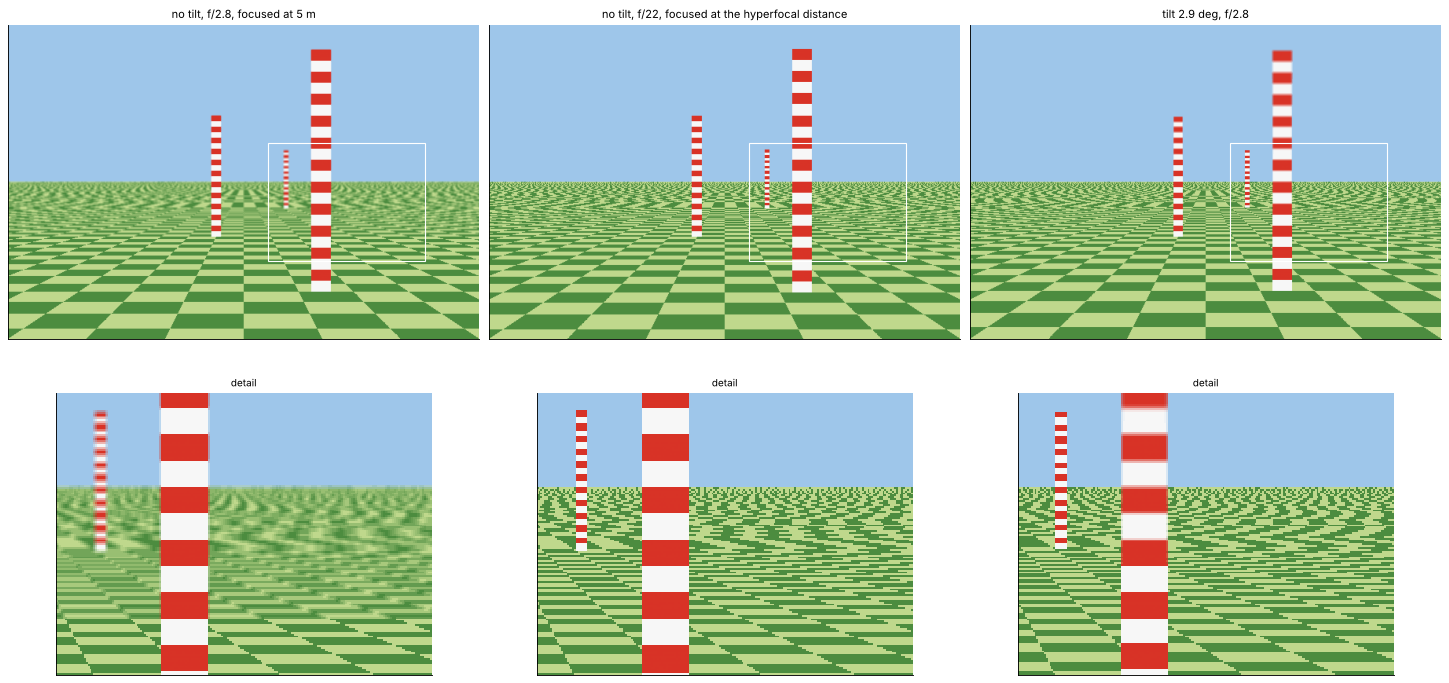

In [12]:
# a meadow with posts, seen by a 50 mm lens 1 m above the ground: three ways to get it sharp
pix = 0.06
nx, ny = 600, 400
xs = (np.arange(nx) + 0.5 - nx/2)*pix
ys_ = (np.arange(ny) + 0.5 - ny/2)*pix
XS, YS = np.meshgrid(xs, ys_)
posts = [(-1200.0, -3000.0), (700.0, -6000.0), (-500.0, -12000.0), (1600.0, -25000.0)]
post_w, post_h = 180.0, 2200.0

def scene(v):
    """Colour and object point of each pixel, seen through the lens centre (sensor at z = v)."""
    P = np.stack([XS, YS, np.full_like(XS, v)], axis=-1)
    D = -P/np.linalg.norm(P, axis=-1)[..., None]
    t = np.full(XS.shape, np.inf)
    with np.errstate(divide="ignore", invalid="ignore"):
        tg = np.where(D[..., 1] < 0, -h/D[..., 1], np.inf)
    col = np.zeros(XS.shape + (3,))
    sky = np.array([0.62, 0.78, 0.92])
    col[:] = sky
    t = tg
    X = D*np.where(np.isfinite(t), t, 1e8)[..., None]
    ground = np.isfinite(tg)
    chk = ((np.floor(X[..., 0]/500) + np.floor(X[..., 2]/500)) % 2).astype(bool)
    col[ground] = np.where(chk[ground][:, None], [0.30, 0.55, 0.25], [0.75, 0.85, 0.55])
    for px, pz in posts:
        tp = pz/D[..., 2]
        Xp = D*tp[..., None]
        hit = (tp > 0) & (tp < t) & (np.abs(Xp[..., 0] - px) < post_w/2) & (Xp[..., 1] > -h) & (Xp[..., 1] < -h + post_h)
        stripe = (np.floor((Xp[..., 1] + h)/100) % 2).astype(bool)
        col[hit] = np.where(stripe[hit][:, None], [0.85, 0.2, 0.15], [0.97, 0.97, 0.97])
        t = np.where(hit, tp, t)
        X = np.where(hit[..., None], Xp, X)
    return col, X

def render(tilt_, v, N_):
    col, X = scene(v)
    b = ph.tilted_blur(X.reshape(-1, 3), 50.0, N_, tilt_, v).reshape(XS.shape)/pix     # blur in pixels
    levels = np.concatenate([[0], np.geomspace(1, 40, 14)])
    k = np.clip(np.searchsorted(levels, b), 0, len(levels) - 1)
    out = np.zeros_like(col)
    for i, L in enumerate(levels):
        sel = k == i
        if not np.any(sel):
            continue
        if L < 1:
            img = col
        else:
            r = L/2
            g = np.arange(-int(r) - 1, int(r) + 2)
            disk = (g[:, None]**2 + g[None, :]**2 <= r**2).astype(float)
            disk /= disk.sum()
            img = np.stack([fftconvolve(np.pad(col[..., c], int(r) + 1, mode="edge"), disk, mode="same")
                            [int(r) + 1:-int(r) - 1, int(r) + 1:-int(r) - 1] for c in range(3)], axis=-1)
        out[sel] = img[sel]
    ground = np.abs(X[..., 1] + h) < 1e-6*h
    sharp_ground = np.mean(b[ground]*pix < C)
    return out, b, sharp_ground, X

f = 50.0
cases = [("no tilt, f/2.8, focused at 5 m", 0.0, f*5000/(5000 - f), 2.8),
         ("no tilt, f/22, focused at the hyperfocal distance", 0.0,
          f*ph.hyperfocal_distance(f, 22, C)/(ph.hyperfocal_distance(f, 22, C) - f), 22),
         ("tilt 2.9 deg, f/2.8", tilt, h*np.tan(tilt), 2.8)]
fig, ax = plt.subplots(2, 3, figsize=(18, 8.6), layout="constrained",
                       gridspec_kw={"height_ratios": [1, 0.75]})
for k, (title, tl, v, N_) in enumerate(cases):
    a = ax[0, k]
    img, b, sg, _ = render(tl, v, N_)
    a.imshow(np.clip(img, 0, 1)[:, ::-1])      # rows from the bottom of the sensor (sky) down; x mirrored back
    a.set_title(title, fontsize=10); a.set_xticks([]); a.set_yticks([])
    a.add_patch(plt.Rectangle((330, 150), 200, 150, fill=False, ec="w", lw=1))
    ax[1, k].imshow(np.clip(img, 0, 1)[:, ::-1][150:300, 330:530], interpolation="nearest")
    ax[1, k].set_xticks([]); ax[1, k].set_yticks([]); ax[1, k].set_title("detail", fontsize=9)
    print("{:50s}: {:.0%} of the ground in the frame within c".format(title, sg))
plt.show()

Untilted at f/2.8 and focused at 5 m, only 29 % of the visible ground is
sharp, and the posts at 12 and 25 m are blurred. Stopped down to f/22 at
the hyperfocal distance, the geometric blur is below $c$ everywhere. But
at f/22 the Airy disk alone is 30 µm (section 2), so the whole image is as
soft as the limit of acceptability, and the exposure is six stops longer.
Tilted by 2.9° at f/2.8, the whole ground is sharp at the wide aperture.
Only the tops of the near posts leave the wedge and blur. This is the
landscape and product photographer's reason for tilt: a fast shutter
speed and diffraction-free sharpness along the subject plane, at the cost
of anything that sticks out of it. The reverse use, a tilt that puts the
plane of focus across the scene, makes the miniature-model look.

## Summary

- Thin lens depth of field: $1/s = 1/s_f \pm (Nc/f^2)(1 - f/s_f)$,
  hyperfocal distance $f^2/Nc + f$ (10.5 m at 50 mm, f/8, 30 µm). With the
  distances measured from the front principal plane, the traced double
  Gauss agrees to 0.5 %. At the same framing the depth,
  $2Nc(1+m)/m^2$, does not depend on the focal length.
- The defocused wave optical MTF (autocorrelation of the pupil with
  $W_{020} = \Delta z/8N^2$) puts the best F-number for 2 m to infinity at
  f/22 to f/24.5 for every frequency tried. Hansma's
  $\sqrt{\Delta v/4.88\lambda} = 21.9$ is within a third of a stop.
- A lens tilted by $\theta$ focuses on a plane through the hinge line at
  $J = f/\sin\theta$, and the sensor plane, the lens plane and the plane of
  focus meet in one line. With $J$ equal to the camera height the ground
  is in focus. A real lens bends that plane with its field curvature: the
  double Gauss focuses 0.2 m above the ground at the edge of the frame, as
  its measured field curvature predicts.
- The depth of field of a tilted lens is a wedge about the hinge line,
  $\pm J$ at the hyperfocal distance and in proportion to the distance
  elsewhere (within 2.5 %). Tilting gives a sharp ground at f/2.8, where an
  untilted lens needs f/22 and runs into diffraction.

In [13]:
print("run time {:.0f} s".format(time.time() - t_start))

run time 12 s


## References

- H. M. Merklinger, *Focusing the View Camera*, self-published (1993), the
  hinge rule and the depth of field wedge.
- H. M. Merklinger, "Scheimpflug's patent", Photo Techniques (Nov./Dec.
  1996).
- T. Scheimpflug, "Improved method and apparatus for the systematic
  alteration or distortion of plane pictures and images by means of
  lenses and mirrors for photography and for other purposes", GB patent
  1196 (1904).
- P. A. Hansma, "View camera focusing in practice", Photo Techniques
  (March/April 1996), the optimum aperture.
- H. H. Hopkins, "The frequency response of a defocused optical system",
  Proc. R. Soc. Lond. A 231, 91–103 (1955).
- H. H. Nasse, "Depth of field and bokeh", Carl Zeiss Camera Lens Division
  (2010).
- S. F. Ray, *Applied Photographic Optics*, 3rd ed., Focal Press (2002),
  chapters 10 (depth of field) and 33 (camera movements).